In [952]:
import pandas as pd 

df = pd.read_csv("covid19.csv")
df = df.fillna(0)
df['Date_reported'] = pd.to_datetime(df['Date_reported'])
df

,Date_reported,Country_code,Country,Continent,WHO_region,New_cases,Cumulative_cases,New_deaths,Cumulative_deaths
0,2020-01-05,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
1,2020-01-12,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
2,2020-01-19,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
3,2020-01-26,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
4,2020-02-02,AF,Afghanistan,Asia,EMRO,0.0,0,0.0,0
...,...,...,...,...,...,...,...,...,...
58555,2024-08-04,ZW,Zimbabwe,Africa,AFRO,1.0,266387,0.0,5740
58556,2024-08-11,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58557,2024-08-18,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740
58558,2024-08-25,ZW,Zimbabwe,Africa,AFRO,0.0,266387,0.0,5740


<Axes: >

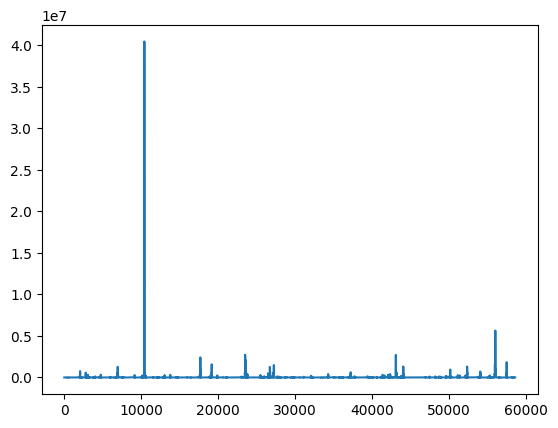

In [953]:
index = df[df["New_cases"] < 0].index
df = df.drop(index)
df["New_cases"].plot()

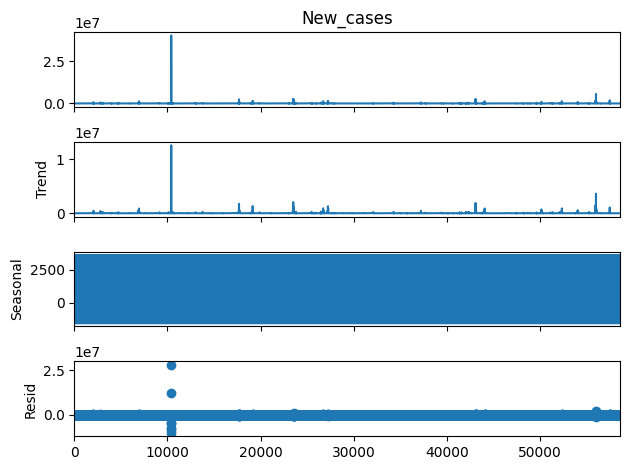

In [954]:
from statsmodels.tsa.seasonal import seasonal_decompose
import matplotlib.pyplot as plt

result = seasonal_decompose(df["New_cases"], period=7)
result.plot()
plt.show()

Date_reported
2020-01-05        2.0
2020-01-12       45.0
2020-01-19       90.0
2020-01-26     1896.0
2020-02-02    12538.0
               ...   
2024-08-04    61561.0
2024-08-11    62947.0
2024-08-18    61055.0
2024-08-25    62487.0
2024-09-01    63361.0
Name: New_cases, Length: 244, dtype: float64


<Axes: xlabel='Date_reported'>

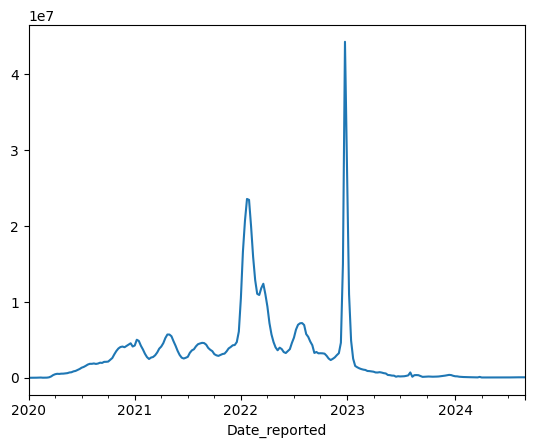

In [955]:
group = df.groupby("Date_reported")["New_cases"].sum()
print(group)
group.plot()

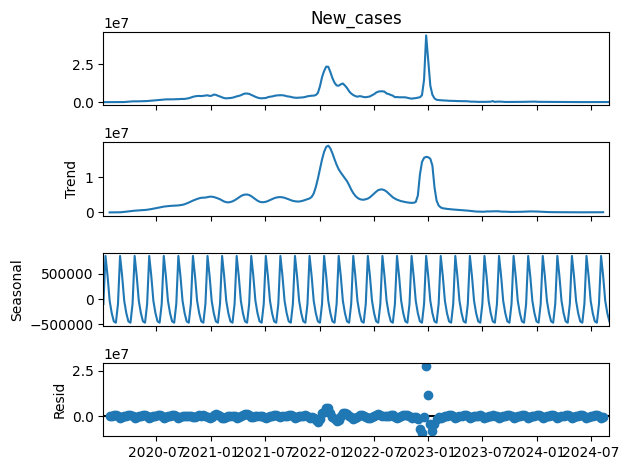

In [956]:
result = seasonal_decompose(group, period=7)
result.plot()
plt.show()

MOVING AVERAGE

In [957]:
# Moving Average (7 hari)

cases = group.reset_index()
cases["Moving_avg"] = cases["New_cases"].rolling(window=7).mean()
cases[["New_cases", "Moving_avg"]].head(10)

,New_cases,Moving_avg
0,2.0,NaN
1,45.0,NaN
2,90.0,NaN
3,1896.0,NaN
4,12538.0,NaN
5,23059.0,NaN
6,31734.0,9909.142857
7,9578.0,11277.142857
8,8273.0,12452.571429
9,20206.0,15326.285714


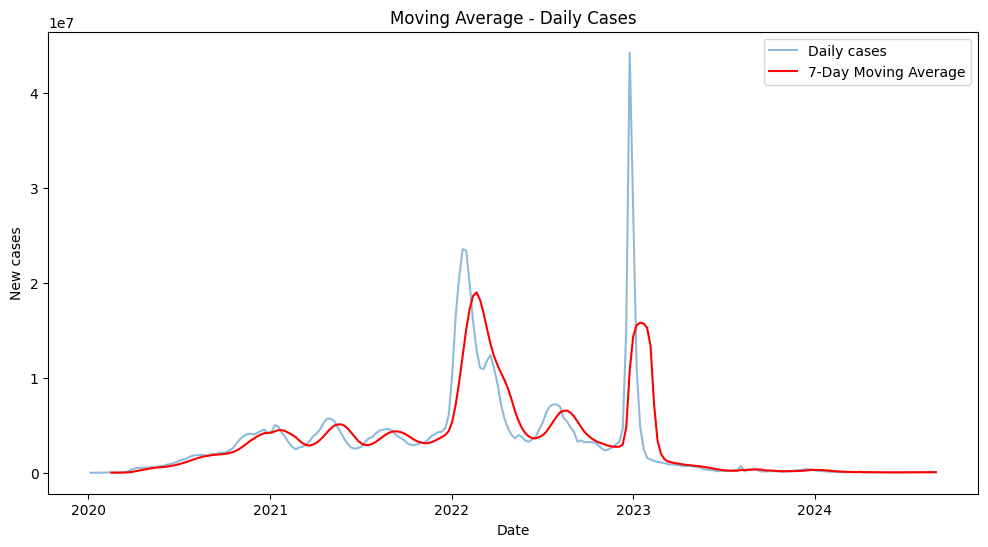

In [958]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(12, 6))
sns.lineplot(x = group.index, y = group.values, label='Daily cases', alpha=0.5)
sns.lineplot(x = cases["Date_reported"], y = cases["Moving_avg"], label='7-Day Moving Average', color='red')
plt.title('Moving Average - Daily Cases')
plt.xlabel('Date')
plt.ylabel('New cases')
plt.legend()
plt.show()

EXPONENTIAL SMOOTHING

In [959]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

single = ExponentialSmoothing(group.values, trend=None, seasonal=None).fit()
double = ExponentialSmoothing(group.values, trend='add', seasonal=None).fit()
triple = ExponentialSmoothing(group.values, trend='add', seasonal="add", seasonal_periods=7).fit()

exponential = pd.DataFrame({
    "Single" : single.fittedvalues,
    "Double" : double.fittedvalues,
    "Triple" : triple.fittedvalues,
})

exponential.head()

/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/holtwinters/model.py:918: ConvergenceWarning: Optimization failed to converge. Check mle_retvals.
  warnings.warn(


,Single,Double,Triple
0,-2154.800000,190.090909,-39475.824119
1,-8.784000,2347.812649,30305.054940
2,44.731080,2401.157127,16732.233460
3,89.773655,2445.968890,12581.824165
4,1886.968868,4243.108227,31438.486022


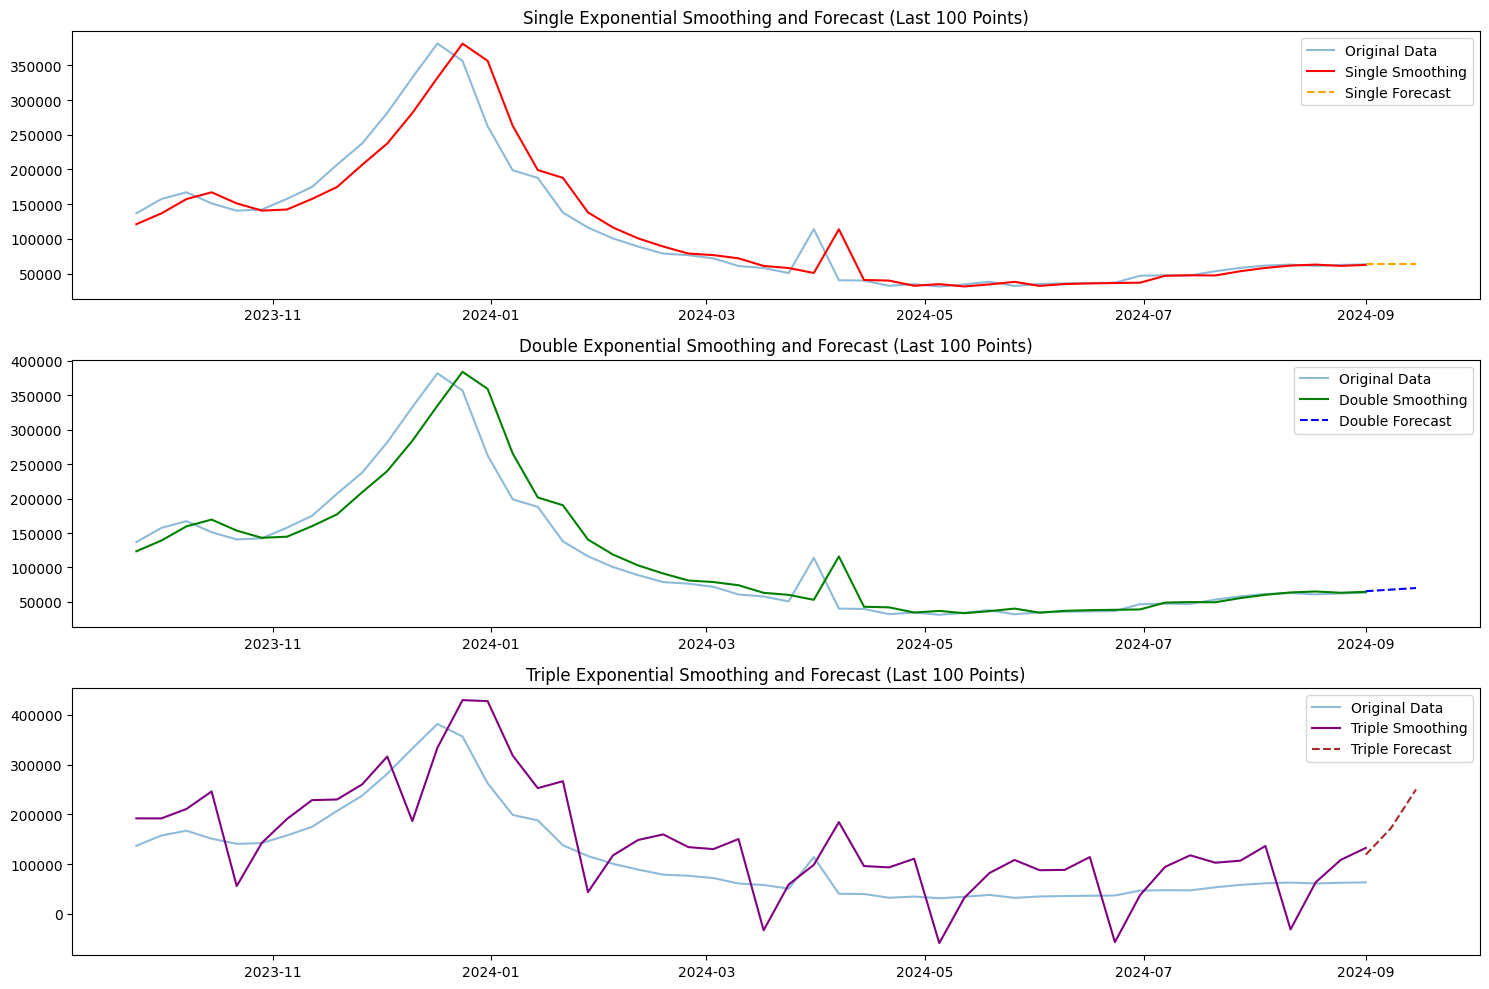

In [960]:
week = 3
single_forecast = single.forecast(steps=week)
double_forecast = double.forecast(steps=week)
triple_forecast = triple.forecast(steps=week)

data = 50  
group_tail = group.tail(data)
index_future = pd.date_range(start=group.index[-1], periods=week, freq='W')

plt.figure(figsize=(15, 10))

# Plot Single Exponential Smoothing
plt.subplot(3, 1, 1)
plt.plot(group_tail.index, group_tail.values, label="Original Data", alpha=0.5)
plt.plot(group_tail.index, single.fittedvalues[-data:], label="Single Smoothing", color='red')
plt.plot(index_future, single_forecast, label="Single Forecast", linestyle="--", color='orange')
plt.title("Single Exponential Smoothing and Forecast (Last 100 Points)")
plt.legend()

# Plot Double Exponential Smoothing
plt.subplot(3, 1, 2)
plt.plot(group_tail.index, group_tail.values, label="Original Data", alpha=0.5)
plt.plot(group_tail.index, double.fittedvalues[-data:], label="Double Smoothing", color='green')
plt.plot(index_future, double_forecast, label="Double Forecast", linestyle="--", color='blue')
plt.title("Double Exponential Smoothing and Forecast (Last 100 Points)")
plt.legend()

# Plot Triple Exponential Smoothing
plt.subplot(3, 1, 3)
plt.plot(group_tail.index, group_tail.values, label="Original Data", alpha=0.5)
plt.plot(group_tail.index, triple.fittedvalues[-data:], label="Triple Smoothing", color='purple')
plt.plot(index_future, triple_forecast, label="Triple Forecast", linestyle="--", color='brown')
plt.title("Triple Exponential Smoothing and Forecast (Last 100 Points)")
plt.legend()

plt.tight_layout()
plt.show()

ARIMA

In [961]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pmdarima import auto_arima
from statsmodels.tsa.arima.model import ARIMA

In [962]:
group_data = df.groupby("Date_reported")[["New_deaths", "New_cases"]].sum()
group_data.head()

,New_deaths,New_cases
Date_reported,,
2020-01-05,3.0,2.0
2020-01-12,1.0,45.0
2020-01-19,2.0,90.0
2020-01-26,56.0,1896.0
2020-02-02,310.0,12538.0


In [963]:
from statsmodels.tsa.stattools import adfuller

adf_cases = adfuller(group_data["New_cases"])
adf_deaths = adfuller(group_data["New_deaths"])
print('p-value new cases:', adf_cases[1])
print('p-value new deaths:', adf_deaths[1])

p-value new cases: 0.00033243623452962193
p-value new deaths: 0.49826778653253073


In [964]:
group_data.index.freq = "W"
len_train = int(len(group_data) * 0.8)
train = group_data[:len_train]
test = group_data[len_train:]

<Axes: xlabel='Date_reported'>

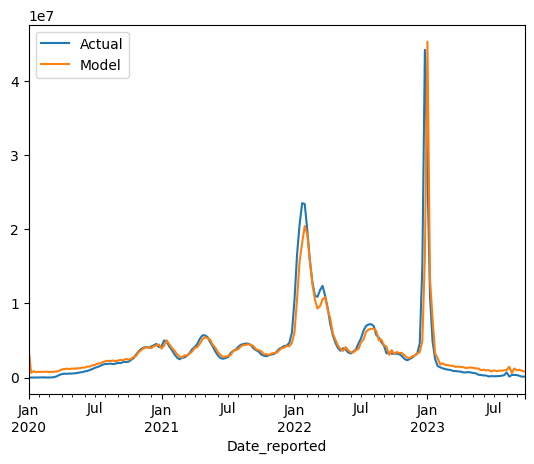

In [965]:
auto = auto_arima(train["New_cases"], 
                  suppress_warnings=True, 
                  error_action="ignore", 
                  stepwise = True)

p, d, q = auto.order

model = ARIMA(train["New_cases"], order=(p, d, q))
model_fit = model.fit()

start = 0
end = len(train) - 1

prediction = model_fit.predict(start, end)

train["New_cases"].plot(label = "Actual", legend = True)
prediction.plot(label = "Model", legend = True)

<Axes: xlabel='Date_reported'>

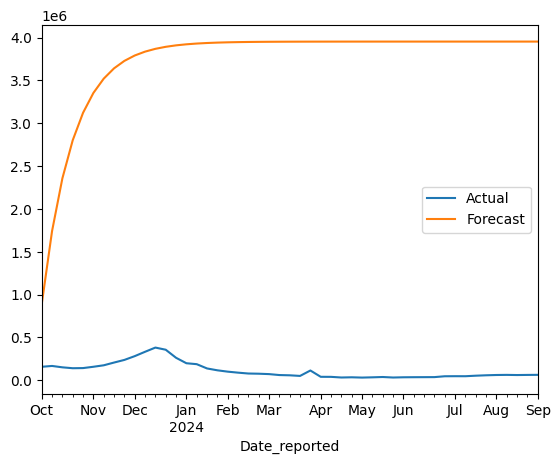

In [966]:
forecast = model_fit.forecast(len(test))
test["New_cases"].plot(label = "Actual", legend = True)
forecast.plot(label = "Forecast", legend = True)

SARIMA

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=6340.956, Time=0.06 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=6590.576, Time=0.01 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=6358.205, Time=0.02 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=6443.554, Time=0.02 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=6676.703, Time=0.00 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=6338.961, Time=0.03 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=6337.002, Time=0.02 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=6338.963, Time=0.04 sec
 ARIMA(1,0,2)(0,0,0)[4] intercept   : AIC=6335.533, Time=0.02 sec
 ARIMA(1,0,2)(1,0,0)[4] intercept   : AIC=6337.492, Time=0.03 sec
 ARIMA(1,0,2)(0,0,1)[4] intercept   : AIC=6337.524, Time=0.05 sec
 ARIMA(1,0,2)(1,0,1)[4] intercept   : AIC=6338.996, Time=0.07 sec
 ARIMA(0,0,2)(0,0,0)[4] intercept   : AIC=6402.633, Time=0.01 sec
 ARIMA(1,0,1)(0,0,0)[4] intercept   : AIC=6333.754, Time=0.01 sec
 ARIMA(1,0,1)(1,0,0)[4] intercept

 This problem is unconstrained.


<Axes: xlabel='Date_reported'>

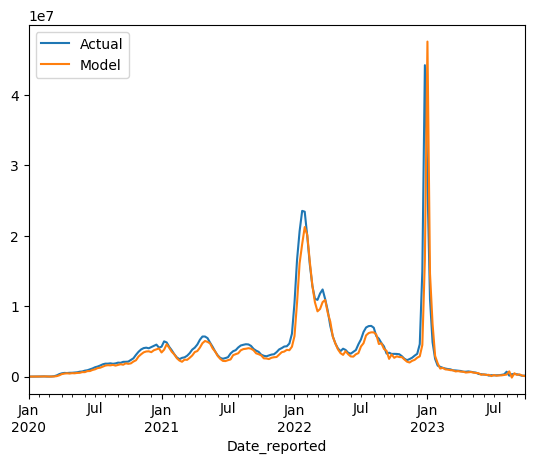

In [967]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima
import pandas as pd
import matplotlib.pyplot as plt

auto = auto_arima(
    train["New_cases"],
    seasonal=True,              
    m=4,                        
    trace=True,
    suppress_warnings=True,
    stepwise=True
)

p, d, q = auto.order
P, D, Q, s = auto.seasonal_order

model = SARIMAX(
    train['New_cases'],
    order=(p, d, q),
    seasonal_order=(P, D, Q, s),
)
model_fit = model.fit()

predictions = model_fit.predict(start=0, end=len(train) - 1)

train["New_cases"].plot(label = "Actual", legend = True)
predictions.plot(label = "Model", legend = True)

<Axes: xlabel='Date_reported'>

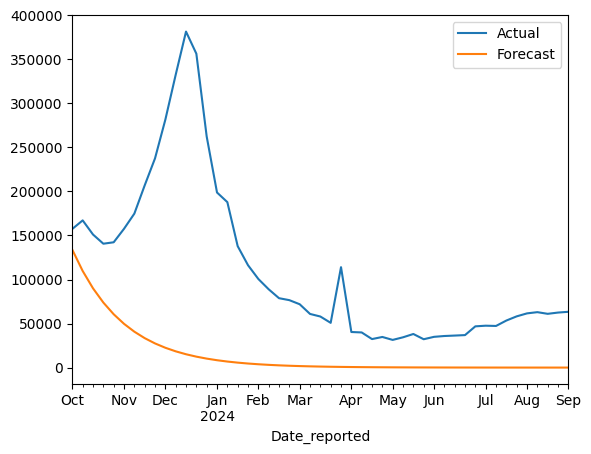

In [968]:
forecast = model_fit.forecast(steps = len(test))

test["New_cases"].plot(label = "Actual", legend = True)
forecast.plot(label = "Forecast", legend = True)

SARIMAX

Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[4] intercept   : AIC=6340.956, Time=0.05 sec
 ARIMA(0,0,0)(0,0,0)[4] intercept   : AIC=6590.576, Time=0.00 sec
 ARIMA(1,0,0)(1,0,0)[4] intercept   : AIC=6358.205, Time=0.01 sec
 ARIMA(0,0,1)(0,0,1)[4] intercept   : AIC=6443.554, Time=0.02 sec
 ARIMA(0,0,0)(0,0,0)[4]             : AIC=6676.703, Time=0.01 sec
 ARIMA(2,0,2)(0,0,1)[4] intercept   : AIC=6338.961, Time=0.04 sec
 ARIMA(2,0,2)(0,0,0)[4] intercept   : AIC=6337.002, Time=0.02 sec
 ARIMA(2,0,2)(1,0,0)[4] intercept   : AIC=6338.963, Time=0.03 sec
 ARIMA(1,0,2)(0,0,0)[4] intercept   : AIC=6335.533, Time=0.01 sec
 ARIMA(1,0,2)(1,0,0)[4] intercept   : AIC=6337.492, Time=0.03 sec
 ARIMA(1,0,2)(0,0,1)[4] intercept   : AIC=6337.524, Time=0.03 sec
 ARIMA(1,0,2)(1,0,1)[4] intercept   : AIC=6338.996, Time=0.03 sec
 ARIMA(0,0,2)(0,0,0)[4] intercept   : AIC=6402.633, Time=0.01 sec
 ARIMA(1,0,1)(0,0,0)[4] intercept   : AIC=6333.754, Time=0.01 sec
 ARIMA(1,0,1)(1,0,0)[4] intercept

 This problem is unconstrained.


<Axes: xlabel='Date_reported'>

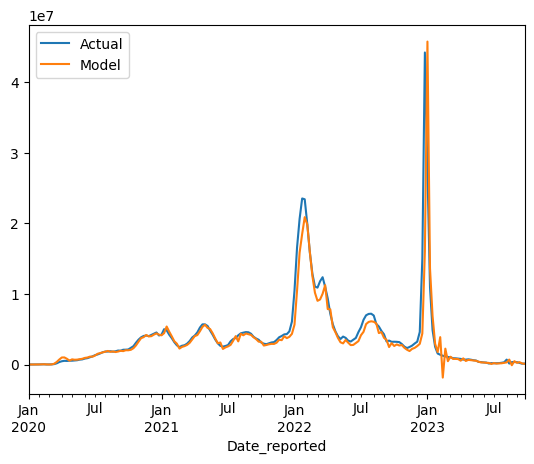

In [969]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima
import pandas as pd
import matplotlib.pyplot as plt

auto = auto_arima(
    train["New_cases"],
    exogenous=train['New_deaths'],  
    seasonal=True,              
    m=4,                        
    trace=True,
    suppress_warnings=True,
    stepwise=True
)

p, d, q = auto.order
P, D, Q, s = auto.seasonal_order

model = SARIMAX(
    train['New_cases'],
    exog=train['New_deaths'],
    order=(p, d, q),
    seasonal_order=(P, D, Q, s),
)
model_fit = model.fit()

predictions = model_fit.predict(start=0, end=len(train) - 1, exog=train["New_cases"])

train["New_cases"].plot(label = "Actual", legend = True)
predictions.plot(label = "Model", legend = True)

<Axes: xlabel='Date_reported'>

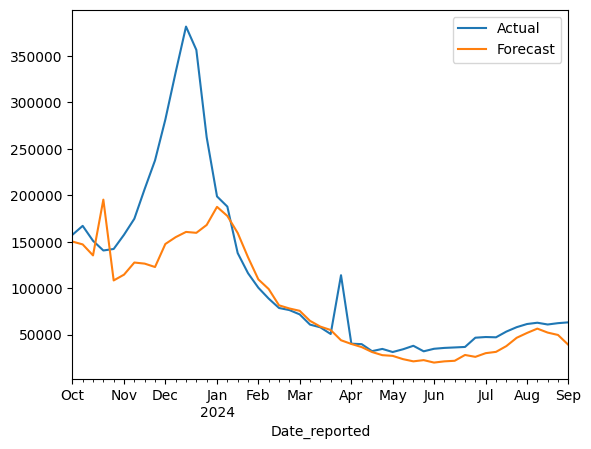

In [970]:
forecast = model_fit.forecast(steps = len(test), exog = test["New_deaths"])
test["New_cases"].plot(label = "Actual", legend = True)
forecast.plot(label = "Forecast", legend = True)

ASSIGNMENT

In [971]:
data = pd.read_csv("Cause-of-Death-Indonesia.csv")
data

,Cause,Type,Year,Data Redundancy,Total Deaths,Source,Page at Source,Source URL
0,Abrasi Air Laut,Bencana Alam,2012,1,0,Profil Kesehatan Indonesia Tahun 2012,Lampiran 3.38,https://pusdatin.kemkes.go.id/download.php?fil...
1,AIDS,Bencana Non Alam dan Penyakit,2000,1,47,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
2,AIDS,Bencana Non Alam dan Penyakit,2001,1,99,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
3,AIDS,Bencana Non Alam dan Penyakit,2002,1,100,Profil Kesehatan Indonesia Tahun 2004,78,https://pusdatin.kemkes.go.id/download.php?fil...
4,AIDS,Bencana Non Alam dan Penyakit,2003,1,261,Profil Kesehatan Indonesia Tahun 2010,115,https://pusdatin.kemkes.go.id/download.php?fil...
...,...,...,...,...,...,...,...,...
675,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2016,1,0,Profil Kesehatan Indonesia Tahun 2016,Lampiran 6.37,https://pusdatin.kemkes.go.id/download.php?fil...
676,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2017,1,0,Profil Kesehatan Indonesia Tahun 2017,Lampiran 6.43,https://pusdatin.kemkes.go.id/download.php?fil...
677,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2019,1,0,Profil Kesehatan Indonesia Tahun 2019,Lampiran 63.c,https://pusdatin.kemkes.go.id/download.php?fil...
678,Wabah Penyakit (Epidemi),Bencana Non Alam dan Penyakit,2020,1,0,Profil Kesehatan Indonesia Tahun 2020,191,https://pusdatin.kemkes.go.id/download.php?fil...


Year
2000       339
2001       324
2002       435
2003       633
2004    220744
Name: Total Deaths, dtype: int64


<Axes: xlabel='Year'>

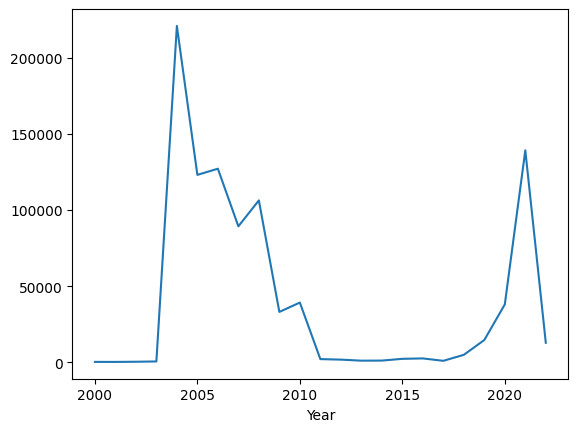

In [979]:
group = data.groupby("Year")["Total Deaths"].sum()
print(group[:5])
group.plot()

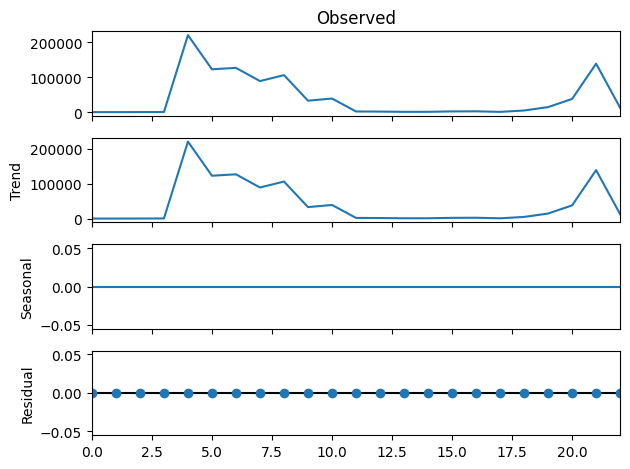

In [973]:
result = seasonal_decompose(group.values, period=1)
result.plot()
plt.show()

In [974]:
group.index = pd.date_range(start='1/1/2000', periods=23, freq='YE').year
group.index = pd.to_datetime(group.index.astype(str), format='%Y')

len_train = int(len(group) * 0.8)
train = group[:len_train]
test = group[len_train:]

In [975]:
adf_total = adfuller(group.values)
print('p-value total deaths:', adf_total[1])

p-value total deaths: 0.05029887098332117


/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)
/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/site-packages/statsmodels/tsa/base/tsa_model.py:473: ValueWarning: No frequency information was provided, so inferred frequency YS-JAN will be used.
  self._init_dates(dates, freq)


<Axes: >

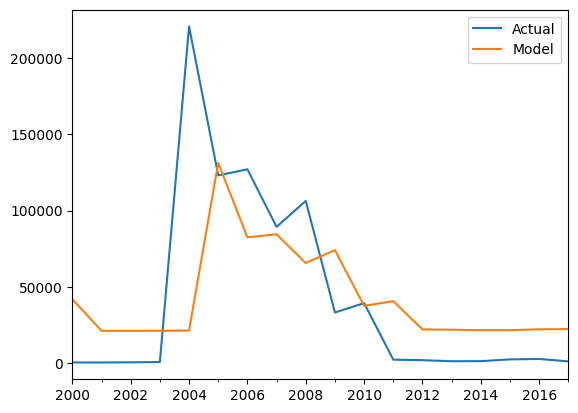

In [976]:
auto = auto_arima(train, 
                  suppress_warnings=True, 
                  error_action="ignore", 
                  stepwise = True)

p, d, q = auto.order

model = ARIMA(train, order=(p, d, q))
model_fit = model.fit()

start = 0
end = len(train) - 1

prediction = model_fit.predict(start, end)

train.plot(label = "Actual", legend = True)
prediction.plot(label = "Model", legend = True)

<Axes: >

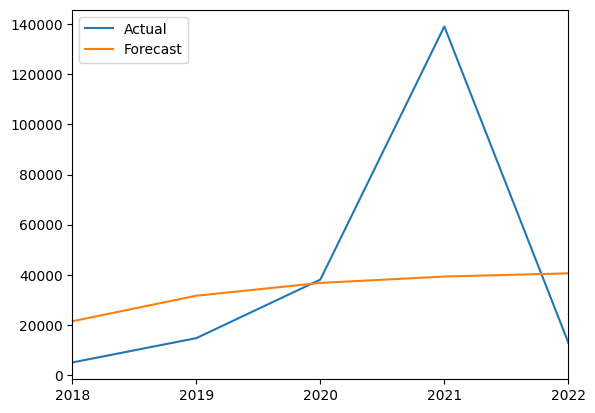

In [977]:
forecast = model_fit.forecast(steps = len(test))
forecast.index = test.index

test.plot(label = "Actual", legend = True)
forecast.plot(label = "Forecast", legend = True)